# Tuần 3 — Cleaning ban đầu, Kiểm tra chất lượng & Thống kê theo ngày


1. Tiền xử lý dataset (cleaning ban đầu): loại duplicate, xử lý NaN, xử lý Infinity, kiểm tra lại datatype
2. Kiểm tra chất lượng dataset sau xử lý
3. Thống kê dữ liệu theo ngày

### 0. Tải dữ liệu đã gán nhãn (tuần 2)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np

LABELED_PATH = "/content/drive/MyDrive/TTTN/cic_ids_2017_labeled.parquet"
df = pd.read_parquet(LABELED_PATH)

shape_before_cleaning = df.shape
print("Shape ban đầu (đầu vào tuần 3):", shape_before_cleaning)
print("Phân bố nhãn:")
print(df["Label_binary"].value_counts())

Shape ban đầu (đầu vào tuần 3): (1778392, 85)
Phân bố nhãn:
Label_binary
0    1496505
1     281887
Name: count, dtype: int64


## 1. Tiền xử lý dataset (cleaning ban đầu)

In [3]:
# 1.1. Loại bỏ dòng trùng lặp (duplicate)
# Không tính cột __source_file khi xét trùng lặp: 2 dòng giống hệt nhau về feature + label
# nhưng khác file nguồn vẫn được coi là dữ liệu trùng lặp về mặt thống kê/học máy.
feature_cols_for_dedup = [c for c in df.columns if c != "__source_file"]

n_before = len(df)
df = df.drop_duplicates(subset=feature_cols_for_dedup).reset_index(drop=True)
n_after_dedup = len(df)

print(f"Số dòng trước khi loại trùng lặp: {n_before:,}")
print(f"Số dòng trùng lặp bị loại: {n_before - n_after_dedup:,}")
print(f"Số dòng còn lại: {n_after_dedup:,}")

Số dòng trước khi loại trùng lặp: 1,778,392
Số dòng trùng lặp bị loại: 39,344
Số dòng còn lại: 1,739,048


In [4]:
# 1.2. Kiểm tra & xử lý giá trị thiếu (NaN)
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

nan_counts = df[num_cols].isnull().sum()
nan_counts = nan_counts[nan_counts > 0]

if len(nan_counts) == 0:
    print("Không có cột nào chứa NaN.")
else:
    print(f"Có {len(nan_counts)} cột chứa NaN:")
    display(nan_counts.to_frame(name="so_luong_nan"))
    n_before_nan = len(df)
    df = df.dropna(subset=num_cols).reset_index(drop=True)
    print(f"Đã loại {n_before_nan - len(df):,} dòng chứa NaN. Số dòng còn lại: {len(df):,}")

Không có cột nào chứa NaN.


In [5]:
# 1.3. Kiểm tra & xử lý giá trị vô cực (Infinity)
# Thường phát sinh ở các đặc trưng dạng tỉ lệ (Flow Bytes/s, Flow Packets/s...) khi mẫu số = 0.
inf_mask = np.isinf(df[num_cols]).any(axis=1)
n_inf = inf_mask.sum()

print(f"Số dòng chứa giá trị Inf: {n_inf:,}")

if n_inf > 0:
    df = df.loc[~inf_mask].reset_index(drop=True)
    print(f"Đã loại {n_inf:,} dòng chứa Inf. Số dòng còn lại: {len(df):,}")
else:
    print("Không có dòng nào chứa Inf -- không cần loại bỏ.")

Số dòng chứa giá trị Inf: 0
Không có dòng nào chứa Inf -- không cần loại bỏ.


In [6]:
# 1.4. Kiểm tra lại kiểu dữ liệu (datatype) từng cột có hợp lý không
dtype_summary = df.dtypes.value_counts()
print("Số lượng cột theo kiểu dữ liệu:")
print(dtype_summary)

print("\nCác cột không phải dạng số (kiểm tra xem có hợp lý không):")
non_numeric_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
print(non_numeric_cols)

Số lượng cột theo kiểu dữ liệu:
float32    43
int8       15
int32      13
int16       9
float64     2
object      2
int64       1
Name: count, dtype: int64

Các cột không phải dạng số (kiểm tra xem có hợp lý không):
['Label', '__source_file']


In [7]:
# Kiểm tra các cột đáng lẽ phải là số nguyên không âm (đếm số lượng gói tin, byte...)
# nhưng lại có giá trị âm -- dấu hiệu dữ liệu lỗi/bất thường.
count_like_cols = [c for c in num_cols if any(k in c for k in
    ["Total", "Count", "Packets", "Bytes", "Length", "Flags", "Header"])]

neg_summary = {}
for c in count_like_cols:
    n_neg = (df[c] < 0).sum()
    if n_neg > 0:
        neg_summary[c] = n_neg

if len(neg_summary) == 0:
    print("Không phát hiện giá trị âm bất thường ở các cột dạng đếm/độ dài.")
else:
    print(f"Có {len(neg_summary)} cột dạng đếm/độ dài chứa giá trị âm (cần lưu ý, xử lý sâu hơn ở tuần 4):")
    display(pd.Series(neg_summary, name="so_luong_am").to_frame())

Không phát hiện giá trị âm bất thường ở các cột dạng đếm/độ dài.


## 2. Kiểm tra chất lượng dataset sau xử lý

In [9]:
# 2.1. So sánh shape trước/sau cleaning
shape_after_cleaning = df.shape

compare = pd.DataFrame(
    [shape_before_cleaning, shape_after_cleaning],
    columns=["so_dong", "so_cot"],
    index=["Trước cleaning ", "Sau cleaning "],
)
compare

,so_dong,so_cot
Trước cleaning,1778392,85
Sau cleaning,1739048,85


In [11]:
# 2.2. Xác nhận không còn duplicate / NaN / Inf
n_dup_remaining = df.duplicated(subset=feature_cols_for_dedup).sum()
n_nan_remaining = df[num_cols].isnull().sum().sum()
n_inf_remaining = np.isinf(df[num_cols]).sum().sum()

print(f"Số dòng trùng lặp còn lại: {n_dup_remaining}")
print(f"Số giá trị NaN còn lại: {n_nan_remaining}")
print(f"Số giá trị Inf còn lại: {n_inf_remaining}")

assert n_dup_remaining == 0 and n_nan_remaining == 0 and n_inf_remaining == 0, "Dữ liệu vẫn còn bị lỗi!"


Số dòng trùng lặp còn lại: 0
Số giá trị NaN còn lại: 0
Số giá trị Inf còn lại: 0


In [17]:
# 2.3. Kiểm tra phân bố nhãn có bị lệch bất thường sau khi cleaning không
label_compare = pd.DataFrame({
    "Số dòng": df["Label_binary"].value_counts().rename({0: "Benign (0)", 1: "Attack (1)"}),
    "Tỉ lệ (%)": df["Label_binary"].value_counts(normalize=True).rename({0: "Benign (0)", 1: "Attack (1)"}).mul(100).round(2),
})
print("Phân bố nhãn SAU cleaning:")
display(label_compare)

Phân bố nhãn SAU cleaning:


,Số dòng,Tỉ lệ (%)
Label_binary,,
Benign (0),1457161,83.79
Attack (1),281887,16.21


## 3. Thống kê dữ liệu theo ngày

In [13]:
# 3.1. Số dòng và số lượng Benign/Attack theo từng ngày (dùng cột __source_file)
day_stats = (
    df.groupby("__source_file")["Label_binary"]
      .agg(so_dong="count", so_attack="sum")
      .assign(so_benign=lambda x: x["so_dong"] - x["so_attack"])
      .assign(ti_le_attack_pct=lambda x: (x["so_attack"] / x["so_dong"] * 100).round(2))
      [["so_dong", "so_benign", "so_attack", "ti_le_attack_pct"]]
)

day_stats

,so_dong,so_benign,so_attack,ti_le_attack_pct
__source_file,,,,
Benign-Monday.parquet,350718,350718,0,0.00
Bruteforce-Tuesday.parquet,306811,299878,6933,2.26
DoS-Wednesday.parquet,459831,288065,171766,37.35
Infiltration-Webattacks-Thursday.parquet,262896,257271,5625,2.14
Portscan-DDos-Botnet-Friday.parquet,358792,261229,97563,27.19


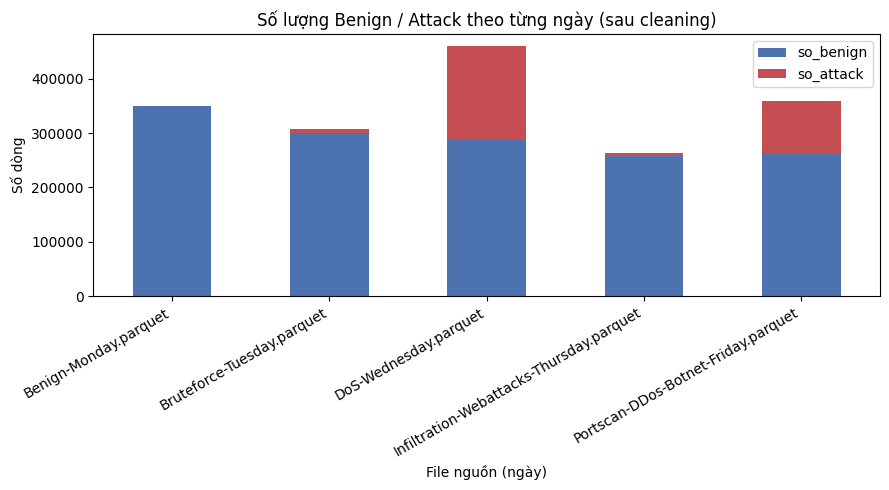

In [14]:
# 3.2. Biểu đồ số lượng Benign/Attack theo từng ngày
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
day_stats[["so_benign", "so_attack"]].plot(kind="bar", stacked=True, ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title("Số lượng Benign / Attack theo từng ngày (sau cleaning)")
ax.set_xlabel("File nguồn (ngày)")
ax.set_ylabel("Số dòng")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [15]:
# 3.3. Loại tấn công nào xuất hiện ở ngày nào
attack_by_day = pd.crosstab(df["Label"], df["__source_file"])
attack_by_day

__source_file,Benign-Monday.parquet,Bruteforce-Tuesday.parquet,DoS-Wednesday.parquet,Infiltration-Webattacks-Thursday.parquet,Portscan-DDos-Botnet-Friday.parquet
Label,,,,,
Benign,350718,299878,288065,257271,261229
Botnet,0,0,0,0,736
DDoS,0,0,0,0,95144
DoS GoldenEye,0,0,7567,0,0
DoS Hulk,0,0,158449,0,0
DoS Slowhttptest,0,0,1741,0,0
DoS Slowloris,0,0,3998,0,0
FTP-Patator,0,3972,0,0,0
Heartbleed,0,0,11,0,0


## 4. Lưu kết quả đã cleaning để dùng cho tuần 4

In [16]:
import os

OUT_DIR = "/content/drive/MyDrive/TTTN/tuan3_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

OUTPUT_PATH = f"{OUT_DIR}/cic_ids_2017_cleaned.parquet"
df.to_parquet(OUTPUT_PATH, index=False)

print("Đã lưu dataset sau cleaning tại:", OUTPUT_PATH)
print("Shape cuối cùng:", df.shape)

Đã lưu dataset sau cleaning tại: /content/drive/MyDrive/TTTN/tuan3_outputs/cic_ids_2017_cleaned.parquet
Shape cuối cùng: (1739048, 85)
